# Student Exam Score Prediction
## Linear Regression with Python

**Objective:** Predict students' exam scores using study hours, clean and visualize the data, train a regression model, evaluate performance, and compare it with polynomial regression.

## Import libraries


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

%matplotlib inline

## Loading the dataset


In [32]:
df = pd.read_csv("StudentPerformanceFactors.csv")
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


## dataset shape


In [33]:
df.shape

(6607, 20)

## Inspect column names


In [34]:
df.columns.tolist()

['Hours_Studied',
 'Attendance',
 'Parental_Involvement',
 'Access_to_Resources',
 'Extracurricular_Activities',
 'Sleep_Hours',
 'Previous_Scores',
 'Motivation_Level',
 'Internet_Access',
 'Tutoring_Sessions',
 'Family_Income',
 'Teacher_Quality',
 'School_Type',
 'Peer_Influence',
 'Physical_Activity',
 'Learning_Disabilities',
 'Parental_Education_Level',
 'Distance_from_Home',
 'Gender',
 'Exam_Score']

Inspect data types and non-null counts

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

## Count missing values

In [36]:
df.isnull().sum()

,0
Hours_Studied,0
Attendance,0
Parental_Involvement,0
Access_to_Resources,0
Extracurricular_Activities,0
Sleep_Hours,0
Previous_Scores,0
Motivation_Level,0
Internet_Access,0
Tutoring_Sessions,0


## Checking duplicate rows

In [37]:
df.duplicated().sum()

np.int64(0)

## Descriptive statistics

In [38]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


## Basic data cleaning


In [39]:
required_columns = ["Hours_Studied", "Exam_Score"]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise KeyError(
        f"Missing expected column(s): {missing_columns}. "
        f"Available columns: {df.columns.tolist()}"
    )

model_df = df[required_columns].copy()

model_df["Hours_Studied"] = pd.to_numeric(
    model_df["Hours_Studied"], errors="coerce"
)
model_df["Exam_Score"] = pd.to_numeric(
    model_df["Exam_Score"], errors="coerce"
)

before_rows = len(model_df)
model_df = model_df.dropna()
print("Rows before cleaning:", before_rows)
print("Rows after cleaning:", len(model_df))

Rows before cleaning: 6607
Rows after cleaning: 6607


## Histogram of study hours


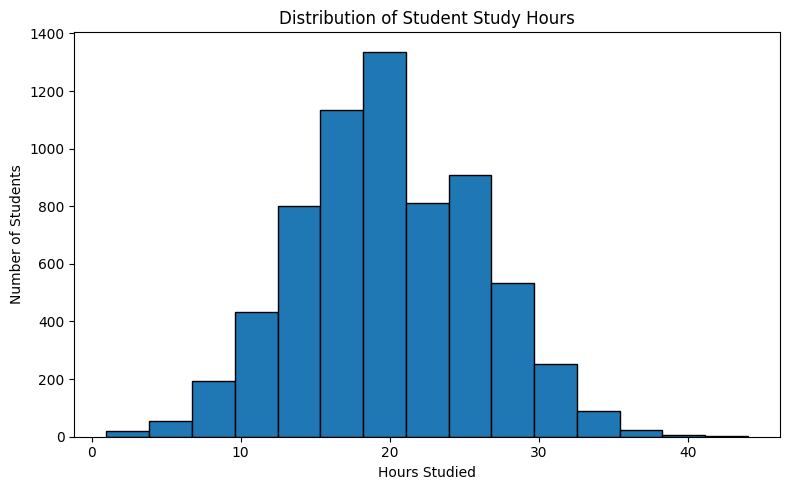

In [40]:
plt.figure(figsize=(8, 5))
plt.hist(model_df["Hours_Studied"], bins=15, edgecolor="black")
plt.title("Distribution of Student Study Hours")
plt.xlabel("Hours Studied")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

## Scatter plot: study hours vs exam scores


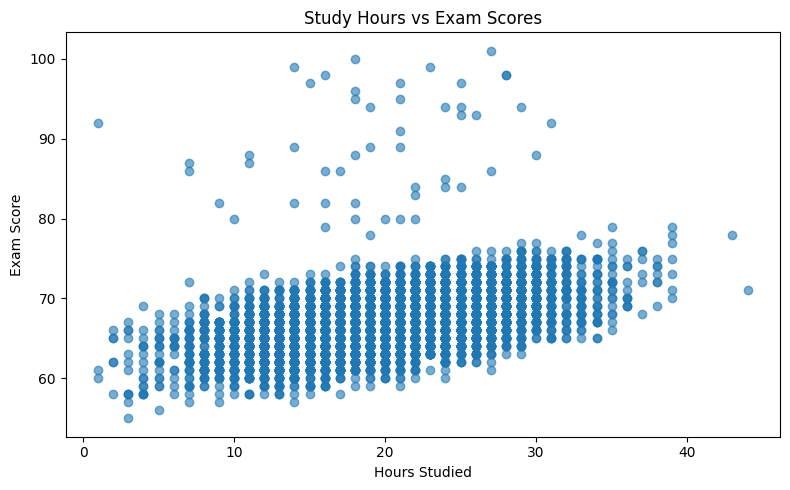

In [41]:
plt.figure(figsize=(8, 5))
plt.scatter(
    model_df["Hours_Studied"],
    model_df["Exam_Score"],
    alpha=0.6
)
plt.title("Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.tight_layout()
plt.show()

## Select input feature and target


In [42]:
X = model_df[["Hours_Studied"]]
y = model_df["Exam_Score"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (6607, 1)
Target shape: (6607,)


## Split into training and testing sets


In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 5285
Testing rows: 1322




## Create the linear regression model

In [44]:
model = LinearRegression()
model

LinearRegression()

## Training the model

In [45]:
model.fit(X_train, y_train)

LinearRegression()

## Inspect the learned equation


In [46]:
intercept = model.intercept_
coefficient = model.coef_[0]

print("Intercept:", round(intercept, 4))
print("Coefficient:", round(coefficient, 4))
print(
    f"Predicted Exam Score = {intercept:.3f} "
    f"+ ({coefficient:.3f} × Hours_Studied)"
)

Intercept: 61.5112
Coefficient: 0.2857
Predicted Exam Score = 61.511 + (0.286 × Hours_Studied)


## Predict exam scores for the test set

In [47]:
y_pred = model.predict(X_test)
y_pred[:10]

array([67.22454236, 67.79587985, 67.5102111 , 64.9391924 , 67.5102111 ,
       67.5102111 , 72.08091101, 68.36721734, 66.36753612, 66.08186738])

## Cell 18 — Compare actual and predicted scores

In [48]:
comparison = pd.DataFrame({
    "Hours Studied": X_test["Hours_Studied"].values,
    "Actual Score": y_test.values,
    "Predicted Score": y_pred
})
comparison["Absolute Error"] = (
    comparison["Actual Score"] - comparison["Predicted Score"]
).abs()

comparison.head(10)

,Hours Studied,Actual Score,Predicted Score,Absolute Error
0,20,65,67.224542,2.224542
1,22,65,67.795880,2.795880
2,21,71,67.510211,3.489789
3,12,64,64.939192,0.939192
4,21,66,67.510211,1.510211
5,21,66,67.510211,1.510211
6,37,72,72.080911,0.080911
7,24,66,68.367217,2.367217
8,17,70,66.367536,3.632464
9,16,70,66.081867,3.918133


## Evaluate linear regression


In [49]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 3))
print("MSE:", round(mse, 3))
print("RMSE:", round(rmse, 3))
print("R² Score:", round(r2, 3))

MAE: 2.448
MSE: 10.856
RMSE: 3.295
R² Score: 0.232


## Cell 20 — Plot the regression line

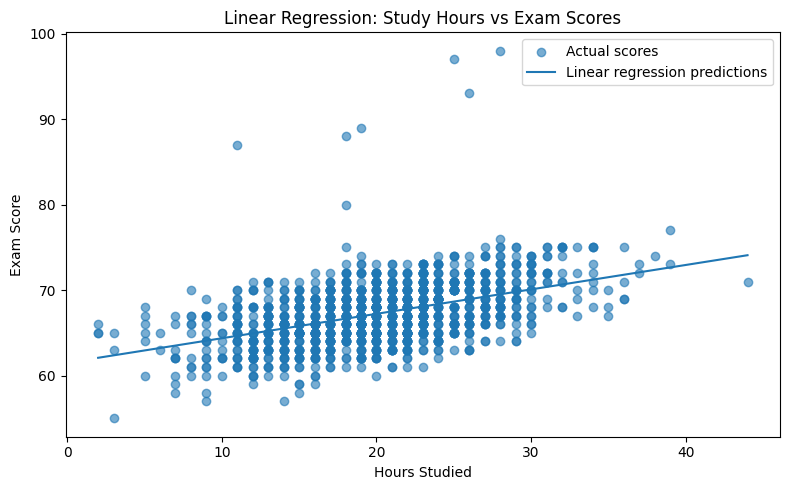

In [50]:
plt.figure(figsize=(8, 5))
plt.scatter(
    X_test["Hours_Studied"],
    y_test,
    label="Actual scores",
    alpha=0.6
)

sort_idx = np.argsort(X_test["Hours_Studied"].to_numpy())
x_sorted = X_test["Hours_Studied"].to_numpy()[sort_idx]
pred_sorted = y_pred[sort_idx]

plt.plot(x_sorted, pred_sorted, label="Linear regression predictions")
plt.title("Linear Regression: Study Hours vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend()
plt.tight_layout()
plt.show()

## Cell 21 — Actual vs predicted plot
Points close to the diagonal line indicate predictions close to actual scores.

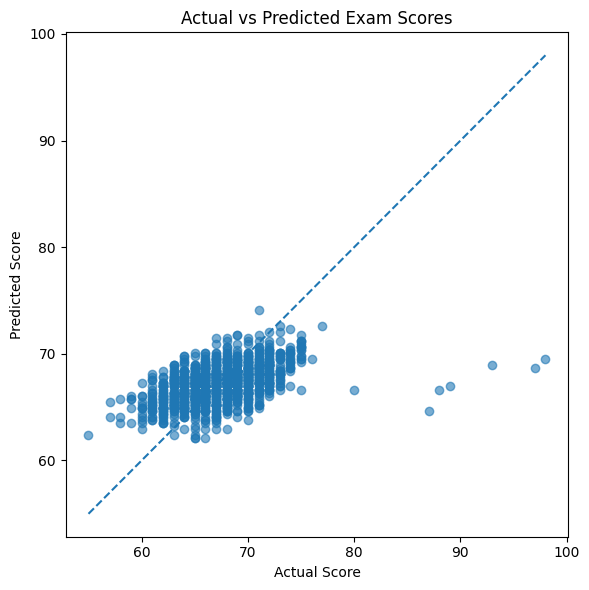

In [51]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)

min_score = min(y_test.min(), np.min(y_pred))
max_score = max(y_test.max(), np.max(y_pred))
plt.plot([min_score, max_score], [min_score, max_score], linestyle="--")

plt.title("Actual vs Predicted Exam Scores")
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.tight_layout()
plt.show()

##Polynomial regression


In [52]:
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)

poly_mae = mean_absolute_error(y_test, poly_pred)
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))
poly_r2 = r2_score(y_test, poly_pred)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (degree 2)"],
    "MAE": [mae, poly_mae],
    "RMSE": [rmse, poly_rmse],
    "R²": [r2, poly_r2]
})

results.round(3)

,Model,MAE,RMSE,R²
0,Linear Regression,2.448,3.295,0.232
1,Polynomial Regression (degree 2),2.445,3.293,0.233


In [53]:
candidate_features = [
    "Hours_Studied",
    "Sleep_Hours",
    "Attendance",
    "Physical_Activity"
]

available_features = [col for col in candidate_features if col in df.columns]
print("Available candidate features:", available_features)

if len(available_features) > 1:
    multi_df = df[available_features + ["Exam_Score"]].copy()

    for col in available_features + ["Exam_Score"]:
        multi_df[col] = pd.to_numeric(multi_df[col], errors="coerce")

    multi_df = multi_df.dropna()
    X_multi = multi_df[available_features]
    y_multi = multi_df["Exam_Score"]

    X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
        X_multi, y_multi, test_size=0.2, random_state=42
    )

    multi_model = LinearRegression()
    multi_model.fit(X_train_multi, y_train_multi)
    multi_pred = multi_model.predict(X_test_multi)

    print("Features:", available_features)
    print("MAE:", round(mean_absolute_error(y_test_multi, multi_pred), 3))
    print("RMSE:", round(np.sqrt(mean_squared_error(y_test_multi, multi_pred)), 3))
    print("R²:", round(r2_score(y_test_multi, multi_pred), 3))
else:
    print("Not enough candidate feature columns were found in this dataset.")

Available candidate features: ['Hours_Studied', 'Sleep_Hours', 'Attendance', 'Physical_Activity']
Features: ['Hours_Studied', 'Sleep_Hours', 'Attendance', 'Physical_Activity']
MAE: 1.465
RMSE: 2.409
R²: 0.59


## Predict a score for a new study-hours value


In [54]:
hours = 5  # Change this value to try a different number of study hours

new_student = pd.DataFrame({"Hours_Studied": [hours]})
predicted_score = model.predict(new_student)[0]

print(f"Study hours: {hours}")
print(f"Predicted exam score: {predicted_score:.2f}")

Study hours: 5
Predicted exam score: 62.94


## all features, with categorical columns encoded

In [55]:
full_df = df.dropna().copy()
full_encoded = pd.get_dummies(full_df, drop_first=True)

X_full = full_encoded.drop(columns="Exam_Score")
y_full = full_encoded["Exam_Score"]

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42
)

full_model = LinearRegression()
full_model.fit(X_train_f, y_train_f)
full_pred = full_model.predict(X_test_f)

print("Rows used:", len(full_encoded))
print("MAE:", round(mean_absolute_error(y_test_f, full_pred), 3))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test_f, full_pred)), 3))
print("R²:", round(r2_score(y_test_f, full_pred), 3))

Rows used: 6378
MAE: 0.487
RMSE: 2.043
R²: 0.731


which features matter most

## Final notes

- The model shows association in this dataset; it does not prove that studying alone causes a particular score.
- A single-feature model is a useful baseline, but student performance can depend on many factors.
- Report the metrics you actually obtain when you run the notebook. Do not invent or assume results.
- For a stronger project, compare feature sets with cross-validation on training data, then evaluate the selected model once on the held-out test set.
